   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [folium]
Note: you may need to restart the kernel to use updated packages.
Cluster Centers (High Coffee Shop Density Areas):
[[ 39.94435238 -75.17731054]
 [ 39.95025801 -75.16421916]
 [ 39.96160618 -75.1732515 ]
 [ 39.94270558 -75.15119465]
 [ 39.96328808 -75.15435835]]


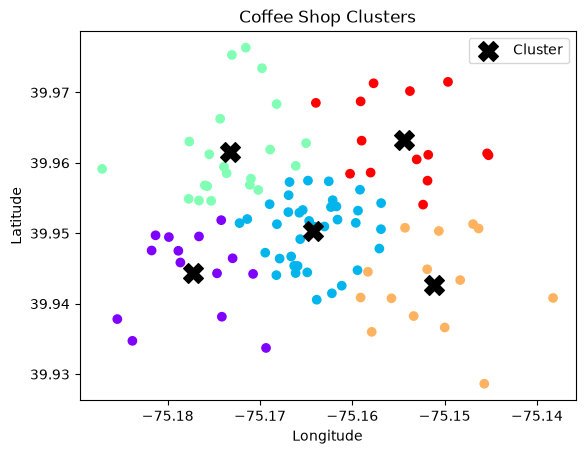


Map saved as coffee_shop_map.html
Open this file in your browser to explore the map.


In [3]:
%pip install folium

import pandas as pd
import numpy as np
import folium
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

city_lat = 39.9526
city_lon = -75.1652
latitudes = np.random.normal(city_lat, 0.01, 100)
longitudes = np.random.normal(city_lon, 0.01, 100)
data = pd.DataFrame({"lat": latitudes, "lon": longitudes})

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(data[["lat", "lon"]]).astype(int)
centers = kmeans.cluster_centers_

print("Cluster Centers (High Coffee Shop Density Areas):")
print(centers)

plt.figure()
plt.scatter(data["lon"], data["lat"], c=data["cluster"], cmap="rainbow")
plt.scatter(
    centers[:, 1],
    centers[:, 0],
    c="black",
    marker="X",
    s=200,
    label="Cluster",
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Coffee Shop Clusters")
plt.legend()
plt.show()

city_map = folium.Map(
    location=[city_lat, city_lon],
    zoom_start=13,
    tiles="OpenStreetMap",
)

colors = ["red", "blue", "green", "purple", "orange"]

for _, row in data.iterrows():
    cluster_id = int(row["cluster"])
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=5,
        color=colors[cluster_id],
        fill=True,
        fill_color=colors[cluster_id],
        popup=f"Cluster {cluster_id}",
    ).add_to(city_map)

for center in centers:
    folium.Marker(
        location=[center[0], center[1]],
        popup="High Density Coffee Shop",
    ).add_to(city_map)

city_map.save("coffee_shop_map.html")
print("\nMap saved as coffee_shop_map.html")
print("Open this file in your browser to explore the map.")


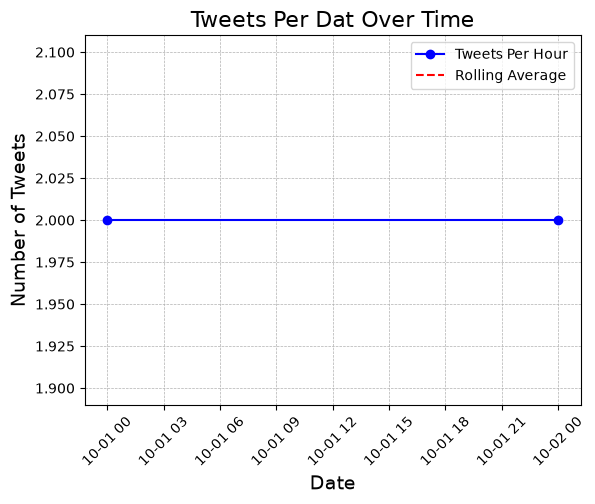

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.DataFrame({
    'data':['20266-10-01 12:00:00', '2026-10-01 13:00:00', '2026-10-02 14:00:00', '2026-10-02 15:00:00'],
    'text':['tweet1', 'tweet2', 'tweet3', 'tweet4'],
})
df["date"] = pd.to_datetime(
    df["data"].str.replace("20266-", "2026-", regex=False),
    errors="coerce",
)
daily_tweets = df.groupby(df['date'].dt.date).size()
plt.figure()
daily_tweets.plot(kind = 'line', marker = 'o', linestyle = '-', color = 'b', label = "Tweets Per Hour")
rolling_avg = daily_tweets.rolling(window=2).mean()
rolling_avg.plot(kind = 'line', linestyle = '--', color = 'red', label = "Rolling Average", ax=plt.gca())
plt.title('Tweets Per Dat Over Time', fontsize = 16)
plt.xlabel('Date', fontsize = 14)
plt.ylabel('Number of Tweets', fontsize = 14)
plt.xticks(rotation = 45)
plt.grid(True, which = 'both', linestyle = '--', linewidth = 0.5)
plt.legend()
plt.show()


In [9]:
from sklearn.metrics.pairwise import cosine_similarity

data = {
    "Movie1": [5, 4, 0, 0, 3],
    "Movie2": [4, 0, 0, 2, 3],
    "Movie3": [0, 0, 5, 4, 0],
    "Movie4": [0, 3, 4, 5, 0],
}

ratings = pd.DataFrame(
    data,
    index=["User1", "User2", "User3", "User4", "User5"],
)

print("User Ratings Matrix:\n")
print(ratings)

similarity = cosine_similarity(ratings)
similarity_df = pd.DataFrame(
    similarity,
    index=ratings.index,
    columns=ratings.index,
)

print("\nUser Similarity Matrix:\n")
print(similarity_df)

user = "User3"
similar_users = similarity_df[user].sort_values(ascending=False)[1:2]
most_sim = similar_users.index[0]

print("\nMost similar user to", user, "is", most_sim)

recom = ratings.loc[most_sim] > 0
not_watched = ratings.loc[user] == 0
final_rec = ratings.columns[recom & not_watched]

print("\nRecommended movies for", user, ":")
print(list(final_rec))


User Ratings Matrix:

       Movie1  Movie2  Movie3  Movie4
User1       5       4       0       0
User2       4       0       0       3
User3       0       0       5       4
User4       0       2       4       5
User5       3       3       0       0

User Similarity Matrix:

          User1     User2     User3     User4     User5
User1  1.000000  0.624695  0.000000  0.186248  0.993884
User2  0.624695  1.000000  0.374817  0.447214  0.565685
User3  0.000000  0.374817  1.000000  0.931240  0.000000
User4  0.186248  0.447214  0.931240  1.000000  0.210819
User5  0.993884  0.565685  0.000000  0.210819  1.000000

Most similar user to User3 is User4

Recommended movies for User3 :
['Movie2']


In [11]:
import numpy as np
X = np.random.rand(200, 2)
y = ((X[:, 0] + X[:, 1]) > 1).astype(int).reshape(-1, 1)

w1 = np.random.randn(2, 4)
b1 = np.zeros((1, 4))
w2 = np.random.randn(4, 1)
b2 = np.zeros((1, 1))
lr = 0.01
epochs = 1000
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
for i in range(epochs):
    z1 = X.dot(w1) + b1
    a1 = np.maximum(0, z1)
    z2 = a1.dot(w2) + b2
    a2 = sigmoid(z2)
    loss = -np.mean(y * np.log(a2 + 1e-8) + (1 - y) * np.log(1 - a2 + 1e-8))
    dz2 = a2 - y
    dw2 = a1.T.dot(dz2) / X.shape[0]
    db2 = np.sum(dz2, axis = 0, keepdims = True) / X.shape[0]
    da1 = dz2.dot(w2.T)
    dz1 = da1 * (z1 > 0)
    dw1 = X.T.dot(dz1) / X.shape[0]
    db1 = np.sum(dz1, axis = 0, keepdims = True) / X.shape[0]
    w2 -= lr * dw2
    b2 -= lr * db2
    w1 -= lr * dw1
    b1 -= lr * db1
    if i % 100 == 0:
        print(f"Epoch {i}, Loss:{loss:.4f}")
y_pred = (a2 > 0.5).astype(int)
accuracy = np.mean(y_pred == y)
print("Accuracy:", accuracy)


Epoch 0, Loss:0.8533
Epoch 100, Loss:0.6417
Epoch 200, Loss:0.6033
Epoch 300, Loss:0.5729
Epoch 400, Loss:0.5474
Epoch 500, Loss:0.5230
Epoch 600, Loss:0.4988
Epoch 700, Loss:0.4762
Epoch 800, Loss:0.4537
Epoch 900, Loss:0.4329
Accuracy: 0.855


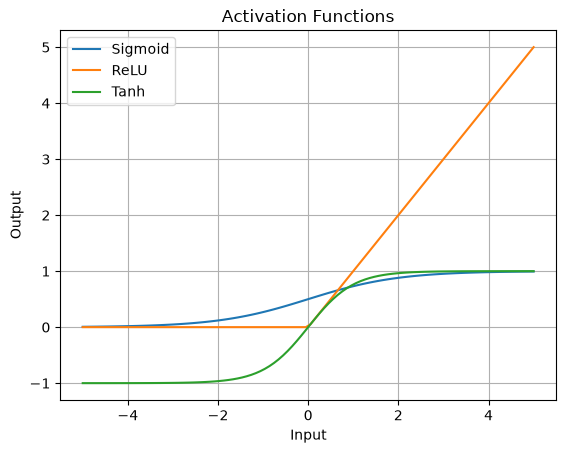

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))
def relu(x):
    return np.maximum(0, x)
def tanh(x):
    return np.tanh(x)
x = np.linspace(-5, 5, 100)

plt.plot(x, sigmoid(x), label = 'Sigmoid')
plt.plot(x, relu(x), label = 'ReLU')
plt.plot(x, tanh(x), label = 'Tanh')
plt.title("Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid(True)
plt.show()


In [14]:
import random
from collections import defaultdict
text = """
I love data science
I love machine learning
data science is fun
machine learning is powerful
python is great for data science
Afrand Agah is currently @ WCU
"""
words = text.lower().split()
model = defaultdict(list)
for i in range(len(words) - 1):
    word = words[i]
    next_word = words[i + 1]
    model[word].append(next_word)

def predict_next(word):
    if word in model:
        return random.choice(model[word])
    else:
        return "No prediction available"

def generate_sentence(start_word, length = 5):
    sentence = [start_word]
    for _ in range(length):
        next_word = predict_next(current_word)
        sentence.append(next_word)
        current_word = next_word
        return " ".join(sentence)

start = input("Enter a starting word: ")
print("Predicted next word:", predict_next(start))
def generate_sentence(start_word, length=5):
    sentence = [start_word]
    current_word = start_word

    for _ in range(length):
        next_word = predict_next(current_word)
        sentence.append(next_word)
        current_word = next_word

    return " ".join(sentence)


print("Generated sentence:", generate_sentence(start))


Predicted next word: No prediction available
Generated sentence: favorite No prediction available No prediction available No prediction available No prediction available No prediction available
